# Project Title: Predicting NYC Property Sale Prices Using Boosting

**Author:** Mayank L Surana

# Problem Statement and Project Objective

Property prices in New York City vary hugely with location, building size, and building type. This project builds a regression model that predicts the sale price of a property from its location and building characteristics. Accurate price estimates help buyers, sellers, and analysts judge whether a listing is fairly priced. The objective is to compare boosting algorithms (AdaBoost, Gradient Boosting, and XGBoost) against a simple Linear Regression baseline and find which one predicts the price best.

# Dataset Description

**Kaggle dataset link:** *(paste the Kaggle link of the NYC housing dataset here)*

The dataset `nyc_housing_base.csv` contains one row per property sale in New York City. Each row has the sale price, the borough and location (latitude and longitude), and building details such as the year built, lot area, building area, residential and commercial area, number of units, number of floors, land use, and building class. The target variable is `sale_price`, and every other useful column is treated as an input feature.

**Note:** check the dataset description and license on the Kaggle page before submitting.

##Importing the Libraries and Loading the Dataset

In [ ]:
import pandas as pd  #pandas for handling datasets
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
uploaded = files.upload()

# Load the CSV file into a DataFrame
df = pd.read_csv("nyc_housing_base.csv")

# Displaying a success message
print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
df.head()  #This is to display the first 5 rows of the uploaded file

,borough_x,block,lot,sale_price,zip_code,borough_y,yearbuilt,lotarea,bldgarea,resarea,comarea,unitsres,unitstotal,numfloors,latitude,longitude,landuse,bldgclass,building_age
0,1,400,11,280000,10009.0,MN,1900.0,2404.0,6875.0,6875.0,0.0,18.0,18.0,5.0,40.724415,-73.983891,2.0,C6,125.0
1,1,402,36,2000000,10009.0,MN,1900.0,1919.0,7810.0,6810.0,1000.0,8.0,10.0,5.0,40.724975,-73.981535,2.0,C4,125.0
2,1,402,60,3400000,10009.0,MN,1920.0,2150.0,6152.0,5352.0,800.0,8.0,9.0,5.0,40.725346,-73.983112,4.0,C7,105.0
3,1,404,42,4000000,10009.0,MN,1855.0,2369.0,6990.0,6990.0,0.0,10.0,10.0,5.0,40.727398,-73.980600,2.0,C4,170.0
4,1,372,55,655000,10009.0,MN,1920.0,5298.0,17990.0,17990.0,0.0,20.0,20.0,5.0,40.720621,-73.979534,2.0,C6,105.0


## Exploring the Dataset Information and Data Types

In [ ]:
print("Dataset Shape:", df.shape) # Display dataset dimensions (rows and columns)

# Display column names, data types, and non-null counts
df.info()

Dataset Shape: (34439, 19)
<class 'pandas.DataFrame'>
RangeIndex: 34439 entries, 0 to 34438
Data columns (total 19 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   borough_x     34439 non-null  int64  
 1   block         34439 non-null  int64  
 2   lot           34439 non-null  int64  
 3   sale_price    34439 non-null  int64  
 4   zip_code      34423 non-null  float64
 5   borough_y     34439 non-null  str    
 6   yearbuilt     34439 non-null  float64
 7   lotarea       34439 non-null  float64
 8   bldgarea      34439 non-null  float64
 9   resarea       34251 non-null  float64
 10  comarea       34251 non-null  float64
 11  unitsres      34439 non-null  float64
 12  unitstotal    34439 non-null  float64
 13  numfloors     34396 non-null  float64
 14  latitude      34433 non-null  float64
 15  longitude     34433 non-null  float64
 16  landuse       34436 non-null  float64
 17  bldgclass     34439 non-null  str    
 18  building_a

In [ ]:
# Display statistical summaries of numerical columns
df.describe()

,borough_x,block,lot,sale_price,zip_code,yearbuilt,lotarea,bldgarea,resarea,comarea,unitsres,unitstotal,numfloors,latitude,longitude,landuse,building_age
count,34439.000000,34439.000000,34439.000000,3.443900e+04,34423.000000,34439.000000,3.443900e+04,3.443900e+04,3.425100e+04,3.425100e+04,34439.000000,34439.000000,34396.000000,34433.000000,34433.000000,34436.000000,34439.000000
mean,3.073608,4562.694532,60.057174,1.171832e+06,10866.464370,1941.007579,5.244022e+04,6.271570e+04,5.593040e+04,6.846554e+03,51.716775,52.309765,4.227674,40.707342,-73.919829,1.943112,83.992421
std,1.287072,3611.017542,136.516558,1.241375e+06,557.770632,28.985203,5.032042e+05,2.712663e+05,2.116029e+05,6.971171e+04,173.385339,174.964326,5.230538,0.082194,0.108336,1.345451,28.985203
min,1.000000,1.000000,1.000000,1.186300e+04,10001.000000,1800.000000,1.610000e+02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,1.000000,40.500291,-74.253599,1.000000,0.000000
25%,2.000000,1432.000000,14.000000,5.125000e+05,10308.000000,1920.000000,2.090000e+03,1.614500e+03,1.356000e+03,0.000000e+00,1.000000,1.000000,2.000000,40.640011,-73.978330,1.000000,65.000000
50%,3.000000,3854.000000,33.000000,8.250000e+05,11210.000000,1935.000000,3.090000e+03,2.494000e+03,2.120000e+03,0.000000e+00,2.000000,2.000000,2.000000,40.705836,-73.915430,1.000000,90.000000
75%,4.000000,6678.000000,59.000000,1.300000e+06,11364.000000,1960.000000,7.502000e+03,1.450000e+04,9.816000e+03,0.000000e+00,13.000000,15.000000,4.000000,40.759718,-73.846150,3.000000,105.000000
max,5.000000,16350.000000,3635.000000,9.995000e+06,11697.000000,2025.000000,2.225160e+07,3.750565e+06,2.690565e+06,1.100000e+06,1887.000000,1906.000000,54.000000,40.912745,-73.700488,11.000000,225.000000


## Checking the Data Quality

In [ ]:
# Count missing values in each column
print("Missing Values:")
print(df.isnull().sum())

# Count the fully duplicated rows
print("\nDuplicate Rows:", df.duplicated().sum())

Missing Values:
borough_x         0
block             0
lot               0
sale_price        0
zip_code         16
borough_y         0
yearbuilt         0
lotarea           0
bldgarea          0
resarea         188
comarea         188
unitsres          0
unitstotal        0
numfloors        43
latitude          6
longitude         6
landuse           3
bldgclass         0
building_age      0
dtype: int64

Duplicate Rows: 1003


In [ ]:
# Mapping the numeric borough code to the borough abbreviation
borough_map = {1: "MN", 2: "BX", 3: "BK", 4: "QN", 5: "SI"}

# Comparing the two borough columns to find the inconsistent rows
mismatch = df["borough_x"].map(borough_map) != df["borough_y"]
print("Rows where the two borough columns disagree:", mismatch.sum())
print("Percentage of rows:", round(mismatch.mean() * 100, 2), "%")

# Counting the rows with zero building area or zero units
print("Rows with zero building area:", (df["bldgarea"] == 0).sum())
print("Rows with zero total units:", (df["unitstotal"] == 0).sum())

Rows where the two borough columns disagree: 9144
Percentage of rows: 26.55 %
Rows with zero building area: 45
Rows with zero total units: 63


**Observation:** The dataset contains duplicate rows, a few missing values, and about a quarter of the rows where `borough_x` and `borough_y` disagree. This mismatch means the building details in those rows likely belong to a different property, so they are not reliable. Some rows also show zero building area or zero units, which is not realistic for a sold property.

##Data Preprocessing - Cleaning the Dataset

In [ ]:
# Check the number of rows before cleaning
print("Rows before cleaning:", df.shape[0])

# Remove the duplicate rows
df = df.drop_duplicates()

# Remove the rows where the two borough columns disagree
df = df[df["borough_x"].map(borough_map) == df["borough_y"]]

# Remove the rows with zero building area, zero units, or a token sale price below $10,000
df = df[(df["bldgarea"] > 0) & (df["unitstotal"] > 0) & (df["sale_price"] >= 10000)]

# Remove the few rows without latitude and longitude
df = df.dropna(subset=["latitude", "longitude"])

# Check the number of rows after cleaning
print("Rows after cleaning:", df.shape[0])

Rows before cleaning: 34439


Rows after cleaning: 24591


In [ ]:
# Fill missing residential area, commercial area, and floors with the median
for col in ["resarea", "comarea", "numfloors"]:
    df[col] = df[col].fillna(df[col].median())

# Fill missing land use with the mode
df["landuse"] = df["landuse"].fillna(df["landuse"].mode()[0])

# Verify missing values after handling
print("Missing values after handling:")
print(df.isnull().sum())

Missing values after handling:
borough_x       0
block           0
lot             0
sale_price      0
zip_code        3
borough_y       0
yearbuilt       0
lotarea         0
bldgarea        0
resarea         0
comarea         0
unitsres        0
unitstotal      0
numfloors       0
latitude        0
longitude       0
landuse         0
bldgclass       0
building_age    0
dtype: int64


In [ ]:
# Grouping the 100+ building classes by their first letter (for example A = one family home)
df["bldgclass_group"] = df["bldgclass"].str[0]

# Treating land use as a category instead of a number
df["landuse"] = df["landuse"].astype(int).astype(str)

print("Building class groups:")
print(df["bldgclass_group"].value_counts())

Building class groups:
bldgclass_group
A    7670
D    6212
B    5558
C    3731
S     650
K     343
O     113
G      98
E      79
F      50
M      46
W      10
P       8
H       7
N       7
I       6
J       2
Z       1
Name: count, dtype: int64


**Data Cleaning Summary:** Duplicate rows, rows with mismatched boroughs, rows with zero area or zero units, and token-price sales were removed. Missing area and floor values were filled with the median, and missing land use was filled with the mode. The building class was grouped by its first letter to reduce 100+ categories to a few groups, and land use was treated as a category.

##Analyzing the Target Variable Distribution

count    2.459100e+04
mean     1.124317e+06
std      1.157687e+06
min      1.186300e+04
25%      5.250000e+05
50%      8.250000e+05
75%      1.250000e+06
max      9.995000e+06
Name: sale_price, dtype: float64


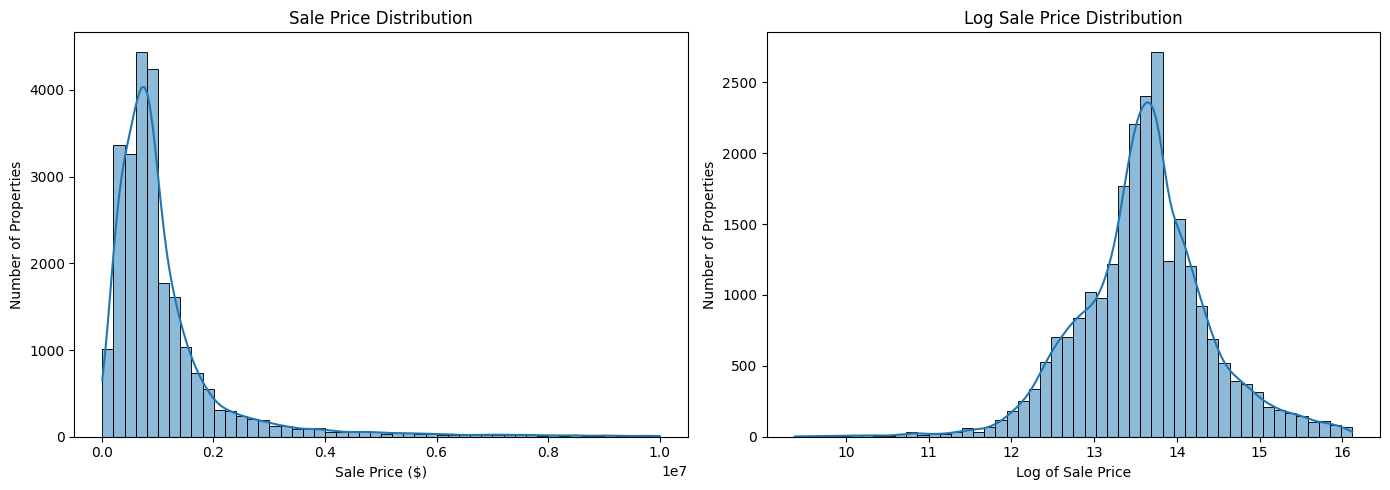

In [ ]:
# Displaying the summary of the sale price
print(df["sale_price"].describe())

# Visualizing the sale price before and after the log transformation
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=df, x="sale_price", bins=50, kde=True, ax=axes[0])
axes[0].set_title("Sale Price Distribution")
axes[0].set_xlabel("Sale Price ($)")
axes[0].set_ylabel("Number of Properties")

sns.histplot(x=np.log1p(df["sale_price"]), bins=50, kde=True, ax=axes[1])
axes[1].set_title("Log Sale Price Distribution")
axes[1].set_xlabel("Log of Sale Price")
axes[1].set_ylabel("Number of Properties")

plt.tight_layout()
plt.show()

**Observation:** The sale price is heavily right-skewed because a few very expensive properties pull the average up. The log transformation makes the distribution much more balanced, so the model will be trained on the log of the price.

##Analyzing the Median Sale Price by Borough

borough_y
BK    1050000.0
MN     879500.0
QN     770000.0
SI     739900.0
BX     710000.0
Name: sale_price, dtype: float64


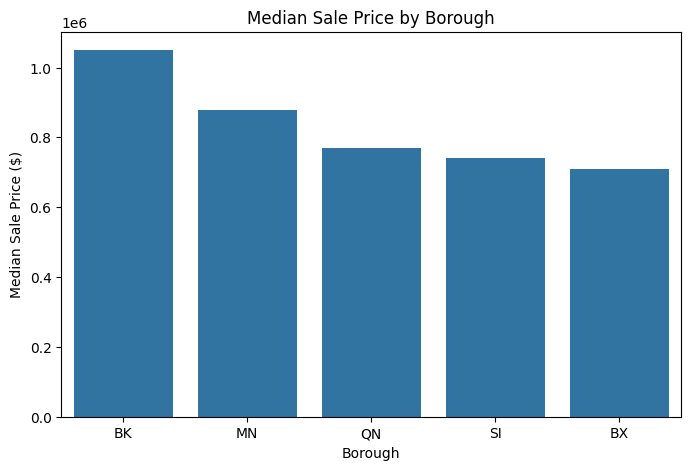

In [ ]:
# Calculating the median sale price for each borough
borough_price = df.groupby("borough_y")["sale_price"].median().sort_values(ascending=False)
print(borough_price)

# Visualizing the median sale price by borough
plt.figure(figsize=(8, 5))
sns.barplot(x=borough_price.index, y=borough_price.values)

plt.title("Median Sale Price by Borough")
plt.xlabel("Borough")
plt.ylabel("Median Sale Price ($)")
plt.show()

**Observation:** Brooklyn has the highest median sale price, followed by Manhattan, while the Bronx has the lowest. Manhattan also has the widest price spread (its average is the highest), so the borough matters for price, but it does not give the full picture.

##Analyzing the Relationship Between Building Area and Sale Price

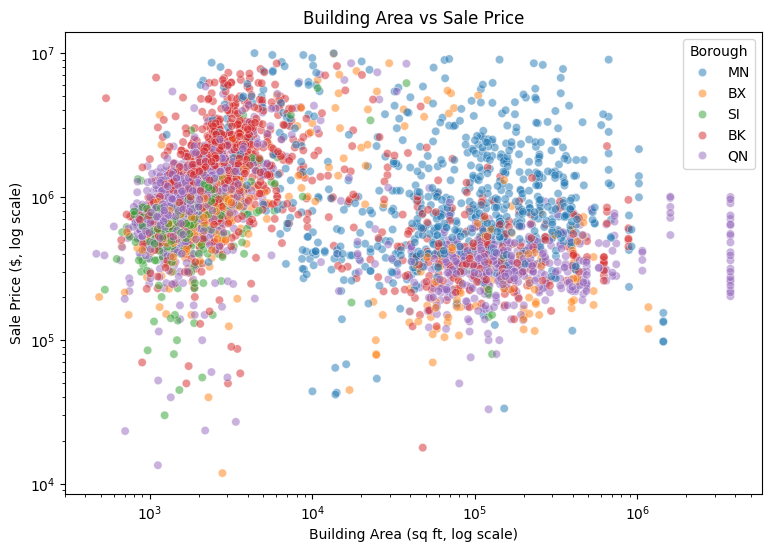

In [ ]:
# Visualizing the building area against the sale price on log scales
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df.sample(5000, random_state=42), x="bldgarea", y="sale_price", hue="borough_y", alpha=0.5)

plt.xscale("log")
plt.yscale("log")
plt.title("Building Area vs Sale Price")
plt.xlabel("Building Area (sq ft, log scale)")
plt.ylabel("Sale Price ($, log scale)")
plt.legend(title="Borough")
plt.show()

##Analyzing the Sale Price by Building Age

age_group
0-25        999000.0
26-50       768000.0
51-75       625000.0
76-100      850000.0
101-125     922746.0
125+       1850000.0
Name: sale_price, dtype: float64


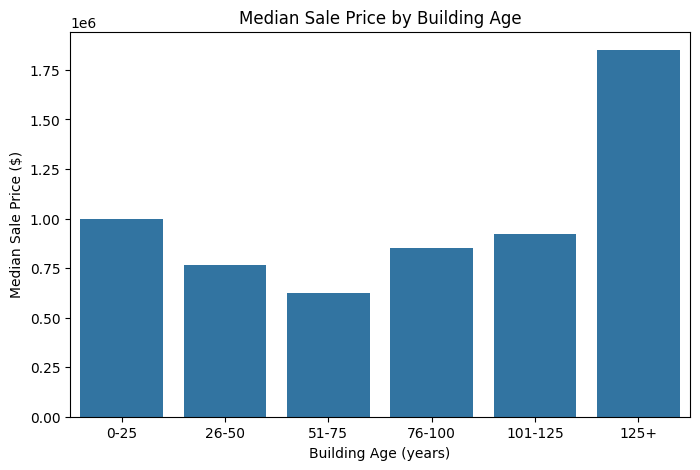

In [ ]:
# Grouping the buildings into age ranges
df["age_group"] = pd.cut(df["building_age"], bins=[-1, 25, 50, 75, 100, 125, 250],
                         labels=["0-25", "26-50", "51-75", "76-100", "101-125", "125+"])

# Visualizing the median sale price for each age group
age_price = df.groupby("age_group", observed=True)["sale_price"].median()
print(age_price)

plt.figure(figsize=(8, 5))
sns.barplot(x=age_price.index, y=age_price.values)

plt.title("Median Sale Price by Building Age")
plt.xlabel("Building Age (years)")
plt.ylabel("Median Sale Price ($)")
plt.show()

# Removing the temporary column after plotting
df = df.drop(columns=["age_group"])

**Observation:** The price does not move in a straight line with age. The median price drops until the 51-75 year group and then rises again, with the oldest buildings (125+ years) having the highest median price. Tree-based boosting models can capture this kind of curved pattern.

##Correlation Heatmap

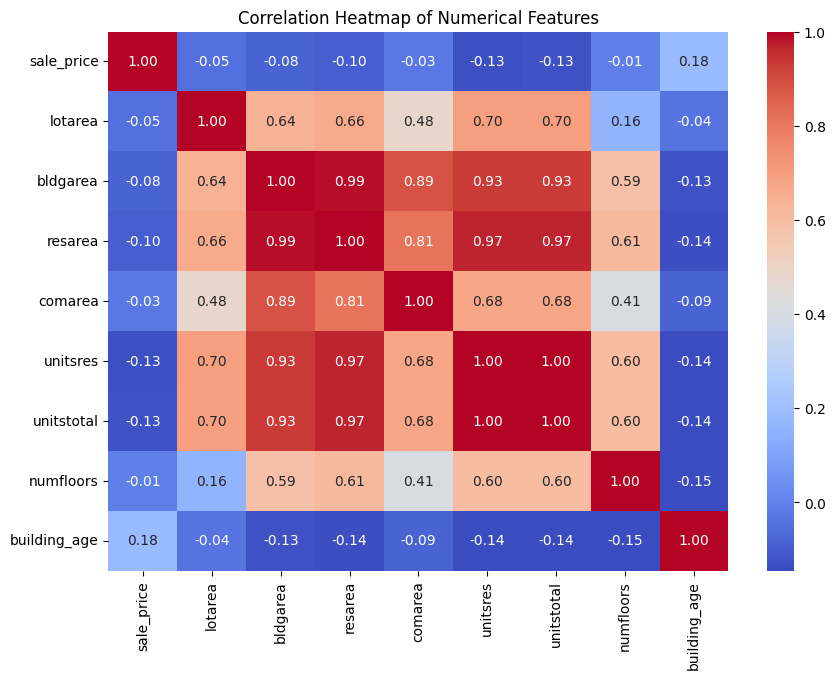

In [ ]:
# Selecting the numerical columns for correlation analysis
numeric_cols = ["sale_price", "lotarea", "bldgarea", "resarea", "comarea", "unitsres", "unitstotal", "numfloors", "building_age"]
correlation = df[numeric_cols].corr()

# Plotting the correlation heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap of Numerical Features")
plt.show()

**Observation:** The area and unit columns are strongly correlated with each other, which is expected because larger buildings have more units. Their correlation with the sale price is weak (slightly negative), and only the building age shows a small positive link, so no single numerical column predicts the price well.

##Preparing the Dataset for Model Training

In [ ]:
print("Available Columns:", df.columns.tolist())

# Separating the target variable from the input features (log of the price is used as the target)
y = np.log1p(df["sale_price"])

# Dropping the target, the duplicate borough code, the IDs, the zip code, and the columns replaced by new ones
X = df.drop(columns=["sale_price", "borough_x", "block", "lot", "zip_code", "yearbuilt", "bldgclass"])

# Displaying the shapes of the input features and target variable
print("Input Features Shape:", X.shape)
print("Target Variable Shape:", y.shape)

Available Columns: ['borough_x', 'block', 'lot', 'sale_price', 'zip_code', 'borough_y', 'yearbuilt', 'lotarea', 'bldgarea', 'resarea', 'comarea', 'unitsres', 'unitstotal', 'numfloors', 'latitude', 'longitude', 'landuse', 'bldgclass', 'building_age', 'bldgclass_group']
Input Features Shape: (24591, 13)
Target Variable Shape: (24591,)


**Decisions:** `borough_x` repeats the borough information, `block` and `lot` are only identification numbers, `zip_code` is covered by latitude and longitude (and has a few missing values), `yearbuilt` is already captured by `building_age`, and `bldgclass` is replaced by its grouped version.

##Encoding Categorical Features

In [ ]:
categorical_columns = X.select_dtypes(include=["object", "string"]).columns
X = pd.get_dummies(X, columns=categorical_columns, drop_first=True, dtype=int)

# Displaying the encoded dataset
print("Encoded Features:")
display(X.head())

# Displaying the updated dataset dimensions
print("Updated Feature Shape:", X.shape)

Encoded Features:


,lotarea,bldgarea,resarea,comarea,unitsres,unitstotal,numfloors,latitude,longitude,building_age,...,bldgclass_group_I,bldgclass_group_J,bldgclass_group_K,bldgclass_group_M,bldgclass_group_N,bldgclass_group_O,bldgclass_group_P,bldgclass_group_S,bldgclass_group_W,bldgclass_group_Z
0,2404.0,6875.0,6875.0,0.0,18.0,18.0,5.0,40.724415,-73.983891,125.0,...,0,0,0,0,0,0,0,0,0,0
1,1919.0,7810.0,6810.0,1000.0,8.0,10.0,5.0,40.724975,-73.981535,125.0,...,0,0,0,0,0,0,0,0,0,0
2,2150.0,6152.0,5352.0,800.0,8.0,9.0,5.0,40.725346,-73.983112,105.0,...,0,0,0,0,0,0,0,0,0,0
3,2369.0,6990.0,6990.0,0.0,10.0,10.0,5.0,40.727398,-73.980600,170.0,...,0,0,0,0,0,0,0,0,0,0
4,5298.0,17990.0,17990.0,0.0,20.0,20.0,5.0,40.720621,-73.979534,105.0,...,0,0,0,0,0,0,0,0,0,0


Updated Feature Shape: (24591, 39)


##Splitting the Dataset into Training and Testing Sets

In [ ]:
# Importing the function for splitting the dataset
from sklearn.model_selection import train_test_split

# Splitting the dataset into 80% training data and 20% testing data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)
print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

Training Features Shape: (19672, 39)
Testing Features Shape: (4919, 39)
Training Target Shape: (19672,)
Testing Target Shape: (4919,)


##Choosing the Approach

This is a **regression problem** because the target is a continuous number (the sale price). Boosting builds many small decision trees one after another, and each new tree focuses on the mistakes of the previous trees. Three boosting models are compared with a Linear Regression baseline:

- **Linear Regression** - simple baseline for comparison
- **AdaBoost Regressor** - boosting that gives more weight to the badly predicted rows
- **Gradient Boosting Regressor** - boosting that fits each new tree to the remaining error
- **XGBoost Regressor** - a faster and more regularized version of gradient boosting

##Building and Training the Models

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import AdaBoostRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor

# Initializing the models with selected hyperparameters
models = {
    "Linear Regression": LinearRegression(),
    "AdaBoost": AdaBoostRegressor(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=300, learning_rate=0.1, max_depth=4, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=600, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8, random_state=42)
}

# Training every model using the training dataset
for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "training completed successfully!")

Linear Regression training completed successfully!


AdaBoost training completed successfully!


Gradient Boosting training completed successfully!


XGBoost training completed successfully!


##Comparing the Model Performance Using R2, RMSE, and MAE

In [ ]:
# Importing the regression evaluation metrics
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

results = []

for name, model in models.items():
    # Generating predictions on the log scale and converting them back to dollars
    pred_log = model.predict(X_test)
    pred_dollar = np.expm1(pred_log)
    actual_dollar = np.expm1(y_test)

    results.append({
        "Model": name,
        "R2 Score (log price)": round(r2_score(y_test, pred_log), 4),
        "RMSE (log price)": round(np.sqrt(mean_squared_error(y_test, pred_log)), 4),
        "MAE ($)": round(mean_absolute_error(actual_dollar, pred_dollar))
    })

# Displaying the comparison table
results_df = pd.DataFrame(results).sort_values(by="R2 Score (log price)", ascending=False)
display(results_df)

,Model,R2 Score (log price),RMSE (log price),MAE ($)
3,XGBoost,0.6101,0.4917,345026
2,Gradient Boosting,0.5857,0.5068,358460
0,Linear Regression,0.3598,0.6300,499941
1,AdaBoost,0.1562,0.7233,587908


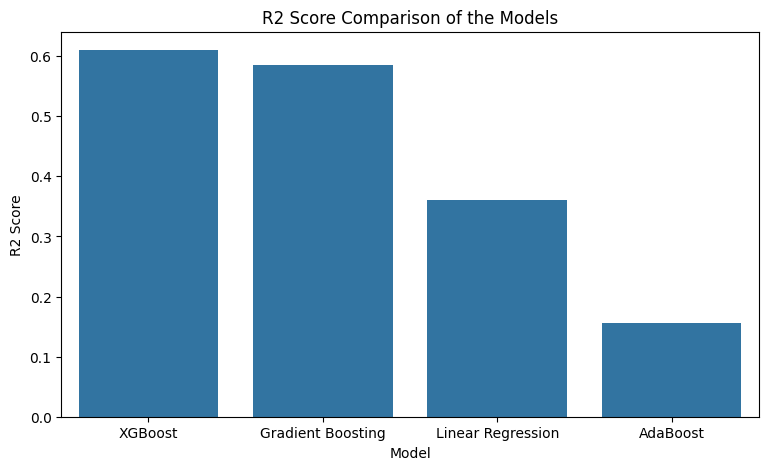

In [ ]:
# Visualizing the R2 score of every model
plt.figure(figsize=(9, 5))
sns.barplot(data=results_df, x="Model", y="R2 Score (log price)")

plt.title("R2 Score Comparison of the Models")
plt.xlabel("Model")
plt.ylabel("R2 Score")
plt.show()

##Visualizing the Actual vs Predicted Prices for the Best Model

Best Model: XGBoost


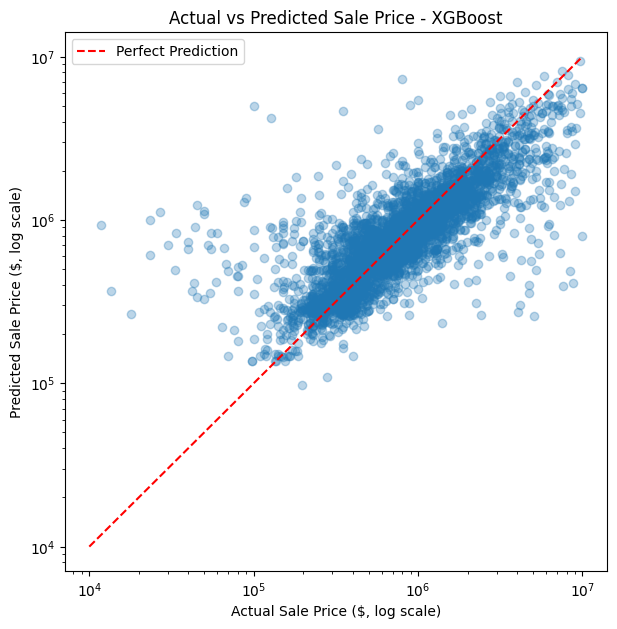

In [ ]:
# Selecting the best model based on the R2 score
best_name = results_df.iloc[0]["Model"]
best_model = models[best_name]
print("Best Model:", best_name)

# Generating the predictions using the best model
y_pred = best_model.predict(X_test)

# Visualizing the actual prices against the predicted prices
plt.figure(figsize=(7, 7))
plt.scatter(np.expm1(y_test), np.expm1(y_pred), alpha=0.3)
plt.plot([1e4, 1e7], [1e4, 1e7], linestyle="--", color="red", label="Perfect Prediction")

plt.xscale("log")
plt.yscale("log")
plt.title("Actual vs Predicted Sale Price - " + best_name)
plt.xlabel("Actual Sale Price ($, log scale)")
plt.ylabel("Predicted Sale Price ($, log scale)")
plt.legend()
plt.show()

##Analyzing the Prediction Errors (Residuals)

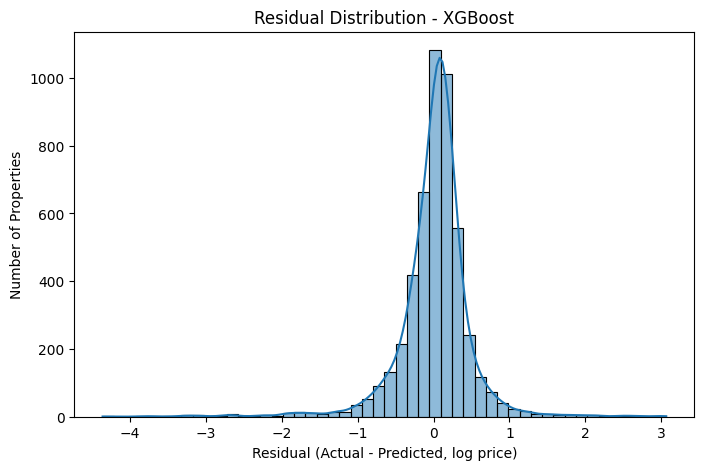

In [ ]:
# Calculating the residuals on the log scale
residuals = y_test - y_pred

# Visualizing the distribution of the residuals
plt.figure(figsize=(8, 5))
sns.histplot(residuals, bins=50, kde=True)

plt.title("Residual Distribution - " + best_name)
plt.xlabel("Residual (Actual - Predicted, log price)")
plt.ylabel("Number of Properties")
plt.show()

##Now looking at the feature importance

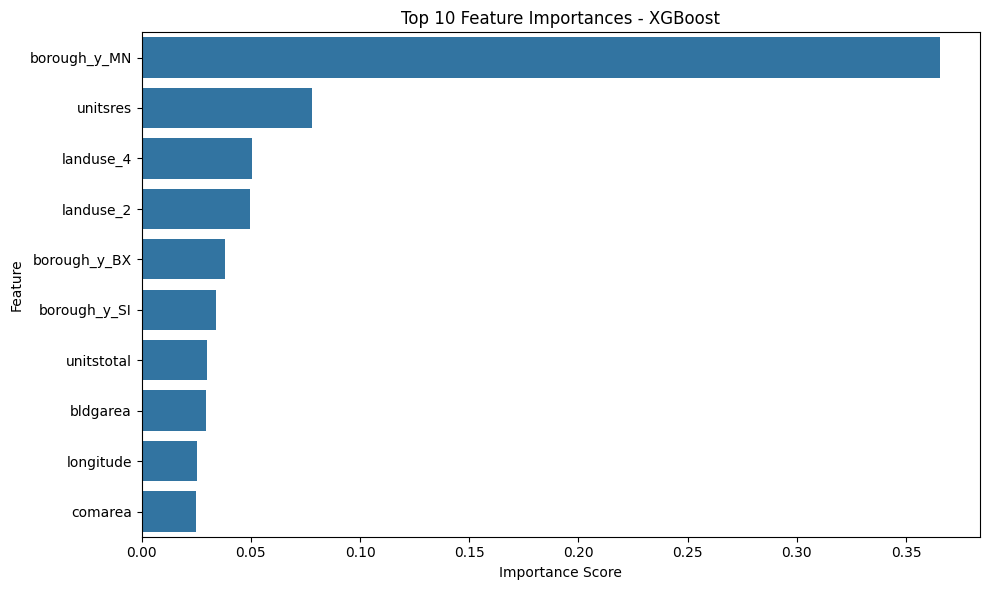

,Feature,Importance
11,borough_y_MN,0.365547
4,unitsres,0.078178
17,landuse_4,0.050607
15,landuse_2,0.049615
10,borough_y_BX,0.038061
13,borough_y_SI,0.033950
5,unitstotal,0.029700
1,bldgarea,0.029490
8,longitude,0.025140
3,comarea,0.024683


In [ ]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": best_model.feature_importances_
})
feature_importance = feature_importance.sort_values(
    by="Importance", ascending=False
)

# Selecting the 10 most important features
top_features = feature_importance.head(10)

# Visualizing the 10 most important features
plt.figure(figsize=(10, 6))
sns.barplot(data=top_features, x="Importance", y="Feature")

plt.title("Top 10 Feature Importances - " + best_name)
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

# Displaying the feature importance rankings
display(top_features)

#CONCLUSION

###Predicting NYC property sale prices using boosting. Comparing boosting models with a linear baseline & identifying the features that influence the price most.

**Key Findings**

- About a quarter of the rows had a borough mismatch between the two borough columns, so removing them was an important cleaning step.
- The sale price is heavily skewed, so the model was trained on the log of the price.
- XGBoost performed the best with an R2 score of 0.61 and an average error of about $345,000. Gradient Boosting followed closely (R2 0.59), while Linear Regression reached only 0.36 and AdaBoost only 0.16.
- Boosting with deeper trees beats the linear model because the price depends on location and building type in a non-linear way.
- Manhattan is the most important feature by a large margin, followed by the number of residential units, the land use type, and the other boroughs.

**Limitations**

- The dataset has no details about the individual unit (bedrooms, floor, condition) and no sale date, so the model cannot learn the market timing.
- An average error of about $345,000 is still large compared with the median price of $825,000.
- Many sales are likely single apartments in large buildings, which makes the building-level columns less reliable.

**Future Improvements**

- Tune the hyperparameters using RandomizedSearchCV or GridSearchCV.
- Add neighborhood-level features such as the average price around each property.
- Add the sale year and more detailed building class information.
- Try LightGBM or CatBoost and compare the results.